In [1]:
import sys
import os
import scipy.ndimage as nd
import scipy.io as io
import numpy as np
import matplotlib.pyplot as plt
import skimage.measure as sk
from utils import utils

plt.style.use('ggplot')

In [2]:
from torch.autograd import Variable
from torchvision import datasets
from torchvision import transforms as tfs
from torch.utils import data

import torch
import PIL.ImageOps

In [3]:
available_device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
from src.vasijas.reporting import ProcessingReport
from _bootstrap import setup

PATHS = setup()
report = ProcessingReport()

In [5]:
transformations = [tfs.RandomHorizontalFlip(p=0.7),
                   tfs.RandomAffine(0, scale=(0.7, 1.), fill=255),
                   tfs.RandomRotation((0, 360), fill=(255, 255, 255)),
                   tfs.Resize((128, 128))]

imagenet_data = datasets.ImageFolder(PATHS.DATA_CENTRADOS, transform=tfs.Compose(transformations))

data_loader = data.DataLoader(imagenet_data, batch_size=4, shuffle=True)

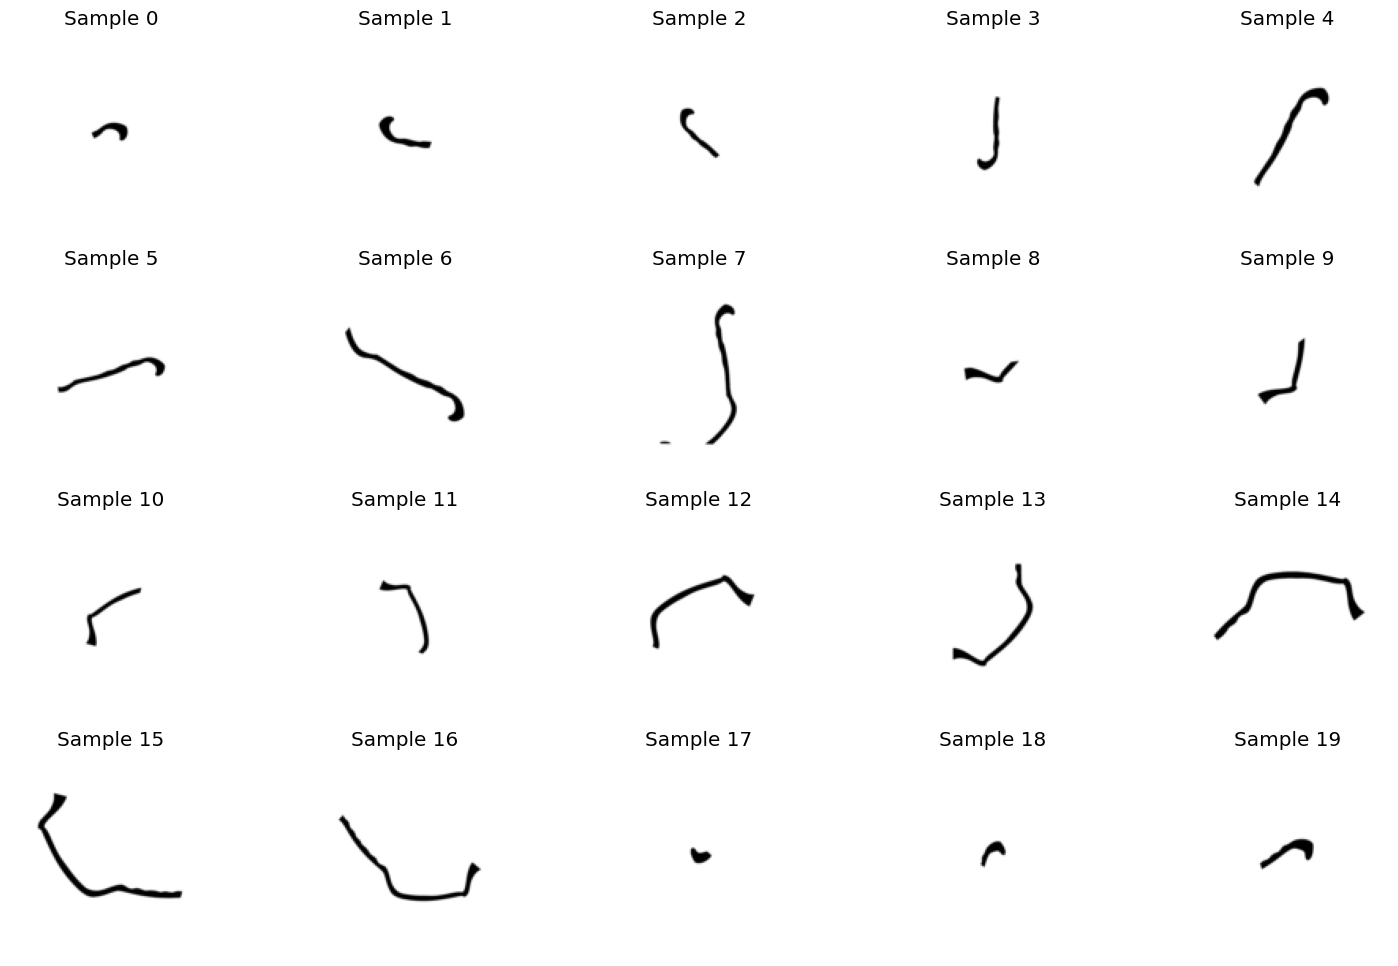

In [7]:
fig = plt.figure(figsize=(15, 10))

n_samples = min(20, max(0, len(imagenet_data) - 10))  # por el offset i+10

for i in range(n_samples):
    sample = imagenet_data[i + 10]  # (imagen, etiqueta)
    ax = plt.subplot(4, 5, i + 1)   # 4 filas x 5 columnas = 20
    plt.tight_layout()
    plt.imshow(np.asarray(sample[0]), cmap=plt.cm.gray_r)
    ax.set_title(f"Sample {i}")
    ax.axis("off")

plt.show()